<p align="center">
  <img src="assets/hero_kavram.svg" width="100%" alt="Gün 53 — Box-Cox ve Yeo-Johnson: kavram dersi">
</p>

<p align="center">
  <img src="https://img.shields.io/badge/G%C3%BCn-53-0B3A52?style=for-the-badge" alt="Gün 53">
  <img src="https://img.shields.io/badge/Konu-Box--Cox_%26_Yeo--Johnson-FF7A59?style=for-the-badge" alt="Konu">
  <img src="https://img.shields.io/badge/Veri-Sigorta_1337_ki%C5%9Fi-0EA5C6?style=for-the-badge" alt="Veri">
  <img src="https://img.shields.io/badge/Seviye-Ba%C5%9Flang%C4%B1%C3%A7-16A34A?style=for-the-badge" alt="Seviye">
</p>

<table>
<tr><td width="25%" valign="top" align="center"><h3>📐</h3><b>Lastik cetvel</b><br><br>Büyük sayıları sıkıştırıp<br><b>küçükleri açan</b> bir cetvel<br><br></td><td width="25%" valign="top" align="center"><h3>🎛️</h3><b>Tek düğme: λ</b><br><br>Bütün bir <b>dönüşüm ailesi</b><br>tek bir sayıyla ayarlanır<br><br></td><td width="25%" valign="top" align="center"><h3>➖</h3><b>Sıfır ve negatif</b><br><br>Box-Cox'un yapamadığını<br><b>Yeo-Johnson</b> yapar<br><br></td><td width="25%" valign="top" align="center"><h3>🛡️</h3><b>Sızıntı tuzağı</b><br><br>λ'yı <b>yalnızca eğitimden</b><br>öğrenmek şart<br><br></td></tr>
</table>

<table><tr><td>

<img src="assets/etiket_hedef.svg" height="34" alt="Hedefler">

**Bu notebook'un sonunda şunları yapabiliyor olacaksınız:**

- 🔔 «Çarpık dağılım» ne demek, neden ortalamayı **yanıltır**, görerek anlamak
- 📐 Dönüşümü bir **lastik cetvel** gibi düşünmek: büyük değerleri sıkıştırır, küçükleri açar
- 🎛️ Box-Cox'un tek düğmesi **λ**'nın ne yaptığını **animasyonla** izlemek
- 🔍 Doğru λ'nın nasıl bulunduğunu («çana en çok benzeyen nokta») sezmek
- ➖ Sıfır ve negatif değerlerde **Yeo-Johnson**'a neden geçildiğini anlamak
- ↩️ Sonucu tekrar **gerçek birime (dolara)** çevirmek
- 🛡️ λ'yı **yalnızca eğitimden** öğrenme kuralını deneyle görmek
- 🌳 Dönüşümün **kime yaradığını** (doğrusal model mi, ağaç mı?) ölçmek

> 🧑‍🎓 **Ön bilgi gerekmiyor.** Formüller bilinçli olarak az tutuldu; her fikir önce bir benzetmeyle, sonra bir deneyle anlatılıyor.

</td></tr></table>

<p align="center">
  <img src="assets/yol_haritasi_kavram.svg" width="100%" alt="Kavram yolculuğu: 10 durak">
</p>

### 🧭 Hızlı Erişim

| # | Durak | # | Durak |
|:-:|:--|:-:|:--|
| 1 | [Kurulum](#k1) | 6 | [Sıfır ve negatif: Yeo-Johnson](#k6) |
| 2 | [Çarpıklık nedir?](#k2) | 7 | [Gidiş-dönüş](#k7) |
| 3 | [Lastik cetvel](#k3) | 8 | [Sızıntı tuzağı](#k8) |
| 4 | [Box-Cox düğmesi](#k4) | 9 | [Doğrusal mı, ağaç mı?](#k9) |
| 5 | [λ'yı bulmak](#k5) | 10 | [Özet, quiz, ödevler](#k10) |

<a id="k1"></a>

<p align="center">
  <img src="assets/kavram_01.svg" width="100%" alt="Durak 1 · Kurulum">
</p>

Kütüphaneleri ve küçük yardımcıları tek hücrede topluyoruz. Dersin boyunca tek bir gerçek veri kullanacağız: **sigorta primleri** (1.338 kişi; her kişinin yıllık sağlık sigortası masrafı).

In [1]:
# ── Kütüphaneler ─────────────────────────────────────────────
import os, time, warnings, sys
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import sklearn
from IPython.display import Image, Markdown, display
from matplotlib.animation import FuncAnimation, PillowWriter

warnings.filterwarnings("ignore")
os.environ["PYTHONWARNINGS"] = "ignore"
RANDOM_STATE = 42
FIG_DIR = Path("outputs/figures"); FIG_DIR.mkdir(parents=True, exist_ok=True)
REP_DIR = Path("outputs/reports"); REP_DIR.mkdir(parents=True, exist_ok=True)

# Renk paleti (sigorta teması: gece mavisi + mercan + nane)
RENK = {"mercan": "#FF7A59", "nane": "#2E9E6B", "amber": "#E5A100", "gok": "#2B8CD6", "mor": "#7C6CE7",
        "gri": "#8A94A6", "koyu": "#14263A", "pembe": "#D1495B"}
plt.rcParams.update({"figure.dpi": 100, "savefig.dpi": 150, "savefig.bbox": "tight", "axes.titleweight": "bold",
                     "axes.titlesize": 13, "axes.grid": True, "grid.alpha": 0.25,
                     "axes.spines.top": False, "axes.spines.right": False})
sns.set_theme(style="whitegrid", rc={"axes.spines.top": False, "axes.spines.right": False, "grid.alpha": 0.25})


def kaydet(fig, ad):
    """Grafiği outputs/figures altına PNG olarak kaydeder."""
    fig.savefig(FIG_DIR / f"{ad}.png")
    print(f"💾 Kaydedildi → outputs/figures/{ad}.png")


def gif_kaydet(kare_ciz, n_kare, ad, figsize=(8.5, 4.4), fps=6):
    """kare_ciz(i, fig) fonksiyonuyla animasyon üretir, GIF olarak kaydeder ve gösterir."""
    fig = plt.figure(figsize=figsize)
    def guncelle(i):
        fig.clear(); kare_ciz(i, fig)
        try: fig.tight_layout()
        except Exception: pass
        return []
    anim = FuncAnimation(fig, guncelle, frames=n_kare, blit=False)
    yol = FIG_DIR / f"{ad}.gif"
    anim.save(yol, writer=PillowWriter(fps=fps), dpi=80)
    plt.close(fig)
    print(f"🎞️ Animasyon → {yol}")
    display(Image(filename=str(yol)))


def rapor_kaydet(df, ad, index=True):
    """Tabloyu outputs/reports altına CSV olarak yazar."""
    df.to_csv(REP_DIR / f"{ad}.csv", index=index, encoding="utf-8-sig")
    print(f"📄 Rapor → outputs/reports/{ad}.csv")

from scipy.special import boxcox as bc_f, inv_boxcox
from sklearn.preprocessing import PowerTransformer
from sklearn.tree import DecisionTreeRegressor
from sklearn.linear_model import LinearRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import mean_squared_error, mean_absolute_error

print("scipy", __import__("scipy").__version__, "| scikit-learn", sklearn.__version__, "| pandas", pd.__version__)

scipy 1.18.1 | scikit-learn 1.9.1 | pandas 3.0.5


In [2]:
# ── Veri: 1.338 kişi, 7 sütun (prim = charges) ──────────────
ham = pd.read_csv("24-insurance.csv")
print("Satır, sütun:", ham.shape, "| aynı satırdan kaç tane daha var:", int(ham.duplicated().sum()))
ham = ham.drop_duplicates().reset_index(drop=True)      # birebir aynı tek satırı çıkarıyoruz (ayrıntı proje dersinde)
prim = ham["charges"].to_numpy()
display(ham.head(4))

Satır, sütun: (1338, 7) | aynı satırdan kaç tane daha var: 1


,age,sex,bmi,children,smoker,region,charges
0,19,female,27.900,0,yes,southwest,16884.92400
1,18,male,33.770,1,no,southeast,1725.55230
2,28,male,33.000,3,no,southeast,4449.46200
3,33,male,22.705,0,no,northwest,21984.47061


<a id="k2"></a>

<p align="center">
  <img src="assets/kavram_02.svg" width="100%" alt="Durak 2 · Çarpıklık nedir">
</p>

### ☕ 2.1 · Kafe Hesabı Benzetmesi

On arkadaş kafeye gidiyor. Dokuz kişi **10 $** harcıyor, bir kişi **1.000 $**. Ortalama harcama **109 $** çıkar; ama masada **109 $ harcayan kimse yok**. Ortalama, uçtaki tek kişi yüzünden gerçek hayatı anlatmaz.

İşte **çarpık dağılım** budur: çoğunluk bir yanda yığılır, **uzun bir kuyruk** diğer yana uzanır. Sigorta primleri, maaşlar, ev fiyatları, site ziyaret süreleri tipik örneklerdir.

<p align="center">
  <img src="assets/diyagram_carpik.svg" width="100%" alt="Çarpık dağılım ve dönüşüm sonrası">
</p>

<table><tr><td>

<img src="assets/etiket_kavram.svg" height="34" alt="Kavram">

**Çarpıklık puanı:** 0 ise dağılım simetriktir. **Pozitif** ise sağ kuyruk uzundur (çok sayıda küçük, az sayıda dev değer). Kabaca |puan| > 1 «belirgin çarpık» sayılır.

</td></tr></table>

💾 Kaydedildi → outputs/figures/kavram_01_carpiklik.png


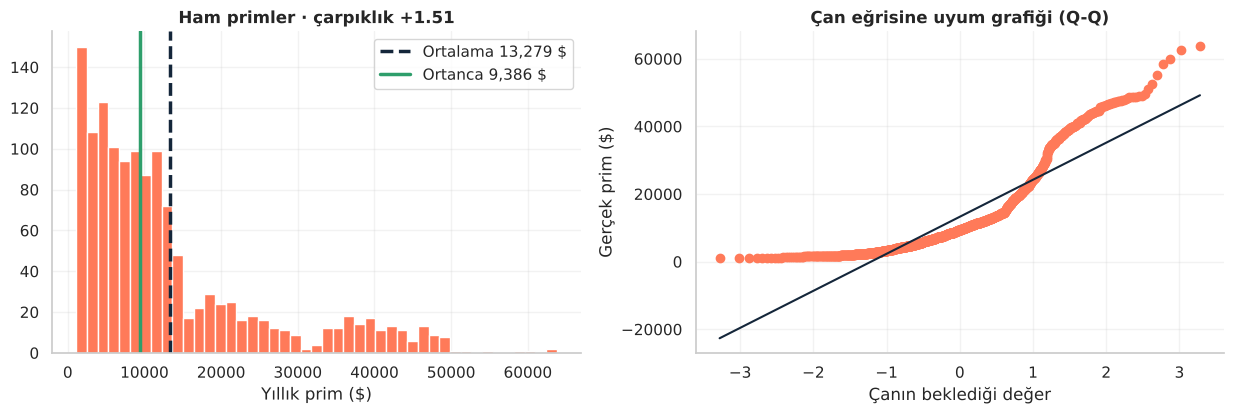

Kişilerin %69'i ortalamanın ALTINDA. Ortalama (13,279 $) ile ortanca (9,386 $) arasında 3,893 $ fark var.


In [3]:
# ── Sigorta primlerinin dağılımı ─────────────────────────────
ort, med = prim.mean(), np.median(prim)
carpiklik = stats.skew(prim)
alt_ort = (prim < ort).mean() * 100

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.3))
ax[0].hist(prim, bins=45, color=RENK["mercan"], edgecolor="white")
ax[0].axvline(ort, color=RENK["koyu"], lw=2.5, ls="--", label=f"Ortalama {ort:,.0f} $")
ax[0].axvline(med, color=RENK["nane"], lw=2.5, label=f"Ortanca {med:,.0f} $")
ax[0].set_title(f"Ham primler · çarpıklık {carpiklik:+.2f}"); ax[0].set_xlabel("Yıllık prim ($)"); ax[0].legend()
stats.probplot(prim, dist="norm", plot=ax[1])
ax[1].get_lines()[0].set_color(RENK["mercan"]); ax[1].get_lines()[1].set_color(RENK["koyu"])
ax[1].set_title("Çan eğrisine uyum grafiği (Q-Q)"); ax[1].set_xlabel("Çanın beklediği değer"); ax[1].set_ylabel("Gerçek prim ($)")
plt.tight_layout(); kaydet(fig, "kavram_01_carpiklik"); plt.show()
print(f"Kişilerin %{alt_ort:.0f}'i ortalamanın ALTINDA. Ortalama ({ort:,.0f} $) ile ortanca ({med:,.0f} $) arasında {ort-med:,.0f} $ fark var.")

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Sağdaki **Q-Q grafiği** bir «çan eğrisi cetveli»dir: noktalar **çizgiye** yapışıksa veri çana benzer. Burada noktalar sağ uçta çizgiden **havaya fırlıyor**; yani birkaç çok yüksek prim, çana göre «fazla uzakta». Dönüşüm bu fırlayan kuyruğu içeri çekmeyi amaçlar.

</td></tr></table>

<a id="k3"></a>

<p align="center">
  <img src="assets/kavram_03.svg" width="100%" alt="Durak 3 · Lastik cetvel">
</p>

### 📐 3.1 · Lastik Cetvel Benzetmesi

Düz bir cetvelde 1 ile 2 arasındaki mesafe, 39 ile 40 arasındaki mesafeyle aynıdır. **Lastik cetvelde** ise büyük sayıların olduğu bölge **sıkışır**, küçük sayıların olduğu bölge **açılır**. Böylece yığılmış küçük değerler birbirinden ayrışır, uzaktaki dev değerler gruba yaklaşır.

<p align="center">
  <img src="assets/diyagram_lastik_cetvel.svg" width="100%" alt="Lastik cetvel">
</p>

Lastiğin ne kadar gerildiğini bir tek sayı belirler: **λ (lambda)**. Önce en bilinen iki lastiği deneyelim: **karekök** ve **logaritma**.

In [4]:
# ── Sekiz küçük sayı üzerinde iki basit "lastik" ─────────────
ornek = np.array([1, 2, 3, 5, 8, 14, 25, 40], dtype=float)
lastik = pd.DataFrame({"ham": ornek, "karekök": np.sqrt(ornek).round(2), "logaritma": np.log(ornek).round(2)})
lastik["ham: son/ilk"] = [ornek[-1] / ornek[0]] + [""] * (len(ornek) - 1)
lastik["karekök: son/ilk"] = [round(np.sqrt(ornek[-1]) / np.sqrt(ornek[0]), 1)] + [""] * (len(ornek) - 1)
display(lastik.style.hide(axis="index"))
print("40 ile 1 arasındaki oran: ham 40 kat → karekökte ~6,3 kat → logaritmada sıfırdan ~3,7'ye. Büyükler sıkıştı.")

ham,karekök,logaritma,ham: son/ilk,karekök: son/ilk
1.000000,1.000000,0.000000,40.000000,6.300000
2.000000,1.410000,0.690000,,
3.000000,1.730000,1.100000,,
5.000000,2.240000,1.610000,,
8.000000,2.830000,2.080000,,
14.000000,3.740000,2.640000,,
25.000000,5.000000,3.220000,,
40.000000,6.320000,3.690000,,


40 ile 1 arasındaki oran: ham 40 kat → karekökte ~6,3 kat → logaritmada sıfırdan ~3,7'ye. Büyükler sıkıştı.


### 🎞️ 3.2 · Canlı Gösteri: Lastiği Gererken Dağılım Nasıl Değişiyor?

Aşağıda **λ düğmesini 1'den aşağı doğru** çeviriyoruz. λ = 1 «hiç dokunma» demektir; λ küçüldükçe sağ kuyruk sıkışır. Sağ üstteki **çarpıklık puanı**nın 0'a yaklaşmasını izleyin.

🎞️ Animasyon → outputs/figures/kavram_02_lastik_gerilir.gif


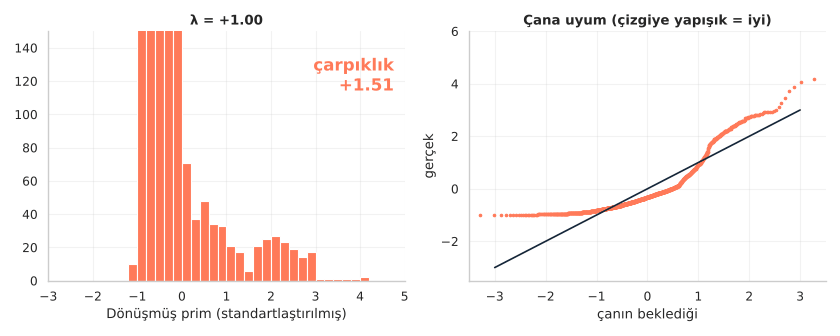

In [5]:
# ── Animasyon: λ 1 → -0.3 (çarpıklık puanı canlı) ────────────
lam_kareler = list(np.linspace(1.0, 0.0, 14)) + [0.0] * 3 + list(np.linspace(0.0, -0.4, 6)) + [-0.4] * 3

def kare_lambda(i, fig):
    lam = lam_kareler[i]
    z = stats.boxcox(prim, lmbda=lam) if lam != 0 else np.log(prim)
    z = (z - z.mean()) / z.std()
    ax = fig.add_subplot(1, 2, 1)
    renk = RENK["mercan"] if abs(stats.skew(z)) > 0.5 else RENK["nane"]
    ax.hist(z, bins=40, color=renk, edgecolor="white", range=(-3, 5))
    ax.set_xlim(-3, 5); ax.set_ylim(0, 150)
    ax.set_title(f"λ = {lam:+.2f}"); ax.set_xlabel("Dönüşmüş prim (standartlaştırılmış)")
    ax.text(0.97, 0.9, f"çarpıklık\n{stats.skew(z):+.2f}", transform=ax.transAxes, ha="right", va="top", fontsize=15, fontweight="bold", color=renk)
    ax2 = fig.add_subplot(1, 2, 2)
    (q, s), (egim, ky, r) = stats.probplot(z, dist="norm")
    ax2.scatter(q, s, s=5, color=renk); ax2.plot([-3, 3], [-3, 3], color=RENK["koyu"], lw=1.5)
    ax2.set_xlim(-3.5, 3.5); ax2.set_ylim(-3.5, 6); ax2.set_title("Çana uyum (çizgiye yapışık = iyi)"); ax2.set_xlabel("çanın beklediği"); ax2.set_ylabel("gerçek")

gif_kaydet(kare_lambda, len(lam_kareler), "kavram_02_lastik_gerilir", figsize=(10.5, 4.2), fps=5)

<table><tr><td>

<img src="assets/etiket_ipucu.svg" height="34" alt="İpucu">

Animasyonda λ **0'a** vardığında dağılım çana en çok yaklaşır (çarpıklık ≈ 0). 0'ı geçip **negatife** gidince lastik **fazla gerilir**, bu kez kuyruk sol tarafa kayar. Yani **«daha çok dönüşüm = daha iyi» değildir**; doğru nokta vardır, onu aramak gerekir (5. durak).

</td></tr></table>

<a id="k4"></a>

<p align="center">
  <img src="assets/kavram_04.svg" width="100%" alt="Durak 4 · Box-Cox düğmesi">
</p>

### 🎛️ 4.1 · Tek Düğme, Koca Bir Aile

Box–Cox dönüşümü (Box & Cox, 1964; Atkinson ve ark., 2021'den aktarma) lastik cetvelleri **tek bir ailede** toplar. Düğme **λ**'dır:

| λ | Ne olur? |
|:-:|:--|
| **1** | Hemen hemen hiçbir şey (sadece kaydırır) |
| **0,5** | Karekök gibi davranır |
| **0** | Logaritma |
| **−1** | Ters çevirme (1/y) gibi; çok güçlü sıkıştırma |

<p align="center">
  <img src="assets/diyagram_lambda_dugme.svg" width="100%" alt="λ düğmesi">
</p>

Formülün tamamı iki satırdır; ezberlemeye gerek yok, ama bir kez görelim:

$$
y^{(\lambda)}=\begin{cases}\dfrac{y^{\lambda}-1}{\lambda}, & \lambda\neq 0\\[2mm] \ln(y), & \lambda=0\end{cases}
$$

<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="Dikkat">

**Tek şart:** Box-Cox yalnızca **pozitif** sayılarla (y > 0) çalışır. Logaritma ve kuvvetler sıfır ya da negatif sayıda sorun çıkarır. 6. durakta çaresine bakacağız.

</td></tr></table>

### ✍️ 4.2 · Elle Hesap: Altı Hastane Faturası

Altı faturamız olsun: **300, 500, 800, 1.500, 4.000, 15.000 $** (sağa doğru uzayan, çarpık bir liste). Düğmeyi iki konuma getirip elle hesaplayalım.

In [6]:
# ── Elle Box-Cox: λ = 0 (logaritma) ve λ = 0,5 ───────────────
fatura = np.array([300, 500, 800, 1500, 4000, 15000], dtype=float)

lam0 = np.log(fatura)                              # λ = 0  → doğal logaritma
lam05 = (fatura ** 0.5 - 1) / 0.5                  # λ = 0,5 → (√y − 1) / 0,5

# kütüphane ile doğrulama (aynı sonucu vermeli)
kutuphane0 = stats.boxcox(fatura, lmbda=0.0)
kutuphane05 = stats.boxcox(fatura, lmbda=0.5)

tablo = pd.DataFrame({"fatura": fatura, "λ=0 (elle)": lam0.round(3), "λ=0 (kütüphane)": kutuphane0.round(3),
                      "λ=0,5 (elle)": lam05.round(1), "λ=0,5 (kütüphane)": kutuphane05.round(1)})
display(tablo.style.hide(axis="index"))
print("En büyük fark (λ=0):", np.abs(lam0 - kutuphane0).max(), "| (λ=0,5):", np.abs(lam05 - kutuphane05).max())
print(f"Çarpıklık: ham {stats.skew(fatura):+.2f} → λ=0,5 {stats.skew(lam05):+.2f} → λ=0 {stats.skew(lam0):+.2f}")

fatura,λ=0 (elle),λ=0 (kütüphane),"λ=0,5 (elle)","λ=0,5 (kütüphane)"
300.000000,5.704000,5.704000,32.600000,32.600000
500.000000,6.215000,6.215000,42.700000,42.700000
800.000000,6.685000,6.685000,54.600000,54.600000
1500.000000,7.313000,7.313000,75.500000,75.500000
4000.000000,8.294000,8.294000,124.500000,124.500000
15000.000000,9.616000,9.616000,242.900000,242.900000


En büyük fark (λ=0): 0.0 | (λ=0,5): 2.842170943040401e-14
Çarpıklık: ham +1.58 → λ=0,5 +1.22 → λ=0 +0.56


<table><tr><td>

<img src="assets/etiket_sonuc.svg" height="34" alt="Sonuç">

Elle hesap ile kütüphane **birebir aynı**. 15.000 $'lık dev fatura, 300 $'lıkla arasındaki 50 katlık farkı logaritmada **yalnızca birkaç birime** indirdi. Bu, lastik cetvelin yaptığı iştir.

</td></tr></table>

<a id="k5"></a>

<p align="center">
  <img src="assets/kavram_05.svg" width="100%" alt="Durak 5 · λ'yı bulmak">
</p>

### 🔍 5.1 · «Çana En Çok Benzeyen» Düğme Konumu

λ'yı elle seçmek yerine bilgisayara şunu soruyoruz: **«Hangi λ'da veri çana en çok benziyor?»** Bunun puanına istatistikte *log-olabilirlik* denir; biz buna **çana benzerlik puanı** diyelim. Puan yüksekse dönüşmüş veri çana yakındır. (λ'nın bu yolla seçilmesi, Box ve Cox'un özgün önerisidir.)

Aşağıdaki animasyonda λ düğmesi soldan sağa gezerken **puan eğrisi** çiziliyor; en tepe nokta aradığımız λ'dır.

En iyi λ = 0.044  (%95 güven aralığı: -0.012 … 0.099)
λ = 0 (logaritma) bu aralığın içinde mi? -> True | λ = 1 (hiç dönüşüm) içinde mi? -> False


🎞️ Animasyon → outputs/figures/kavram_03_lambda_arama.gif


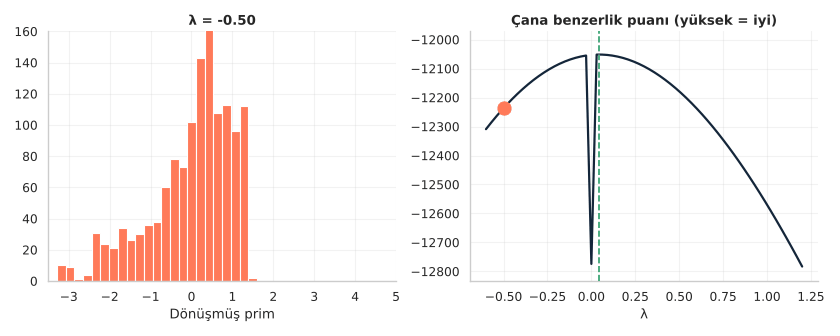

In [7]:
# ── Çana benzerlik puanı eğrisi ve en iyi λ ──────────────────
lam_izgara = np.linspace(-0.6, 1.2, 61)
puan = np.array([stats.boxcox_llf(l, prim) for l in lam_izgara])
lam_en, (alt, ust) = stats.boxcox(prim, alpha=0.05)[1:]
print(f"En iyi λ = {lam_en:.3f}  (%95 güven aralığı: {alt:.3f} … {ust:.3f})")
print("λ = 0 (logaritma) bu aralığın içinde mi? ->", alt <= 0 <= ust, "| λ = 1 (hiç dönüşüm) içinde mi? ->", alt <= 1 <= ust)

gez = list(np.linspace(-0.5, 1.1, 22)) + [lam_en] * 6

def kare_arama(i, fig):
    lam = gez[i]
    ax = fig.add_subplot(1, 2, 1)
    z = stats.boxcox(prim, lmbda=lam); z = (z - z.mean()) / z.std()
    ok = abs(lam - lam_en) < 0.03
    renk = RENK["nane"] if ok else RENK["mercan"]
    ax.hist(z, bins=40, color=renk, edgecolor="white", range=(-3.5, 5)); ax.set_xlim(-3.5, 5); ax.set_ylim(0, 160)
    ax.set_title(f"λ = {lam:+.2f}" + ("   ✅ en iyi" if ok else "")); ax.set_xlabel("Dönüşmüş prim")
    ax2 = fig.add_subplot(1, 2, 2)
    ax2.plot(lam_izgara, puan, color=RENK["koyu"], lw=2)
    ax2.axvline(lam_en, color=RENK["nane"], ls="--", lw=1.5)
    ax2.scatter([lam], [stats.boxcox_llf(lam, prim)], s=140, color=renk, zorder=5)
    ax2.set_title("Çana benzerlik puanı (yüksek = iyi)"); ax2.set_xlabel("λ")
    ax2.set_ylim(puan.min() - 50, puan.max() + 80)

gif_kaydet(kare_arama, len(gez), "kavram_03_lambda_arama", figsize=(10.5, 4.2), fps=5)

💾 Kaydedildi → outputs/figures/kavram_04_oncesi_sonrasi.png


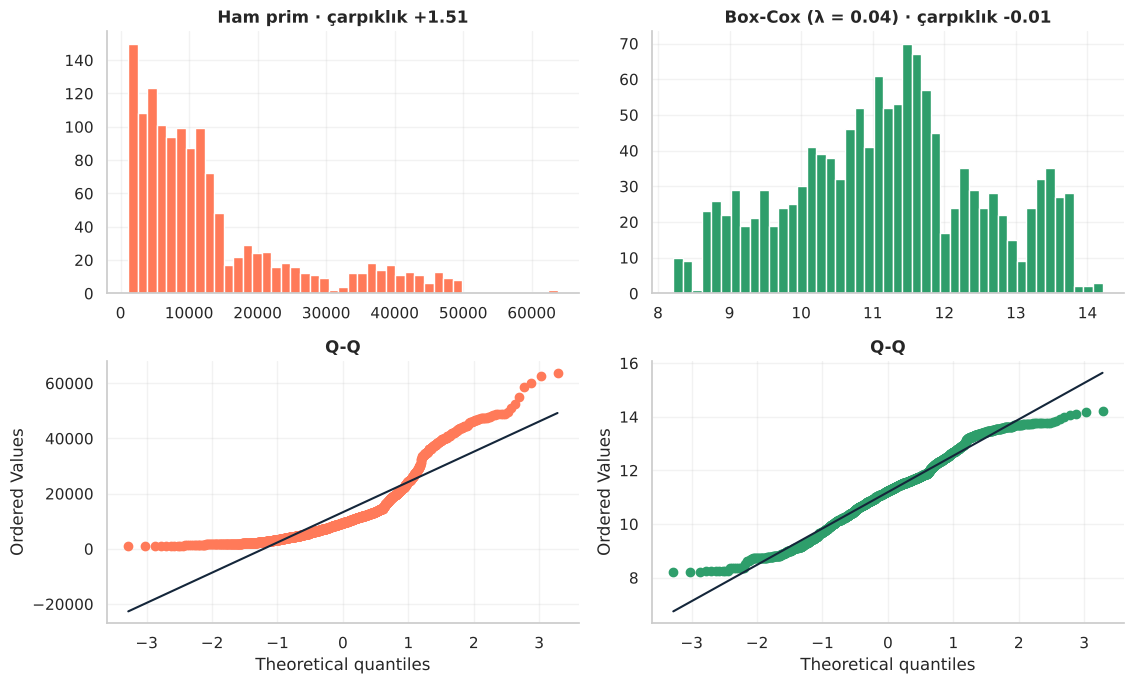

In [8]:
# ── Dönüşüm öncesi ve sonrası, yan yana ─────────────────────
z_bc, _ = stats.boxcox(prim)
fig, ax = plt.subplots(2, 2, figsize=(11.5, 7))
for j, (v, ad, r) in enumerate([(prim, "Ham prim", RENK["mercan"]), (z_bc, f"Box-Cox (λ = {lam_en:.2f})", RENK["nane"])]):
    ax[0, j].hist(v, bins=45, color=r, edgecolor="white"); ax[0, j].set_title(f"{ad} · çarpıklık {stats.skew(v):+.2f}")
    stats.probplot(v, dist="norm", plot=ax[1, j]); ax[1, j].get_lines()[0].set_color(r); ax[1, j].get_lines()[1].set_color(RENK["koyu"]); ax[1, j].set_title("Q-Q")
plt.tight_layout(); kaydet(fig, "kavram_04_oncesi_sonrasi"); plt.show()

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

Bu veride en iyi λ **0'a çok yakın** çıktı; yani Box-Cox burada pratikte **logaritma** seçti. Q-Q grafiğinde sağ kuyruk büyük ölçüde çizgiye yaklaştı. **Ama** sol alt bölgede hâlâ bir sapma var: veri tek bir tepe değil, **birkaç grubun** karışımıdır (sigara içenler ve içmeyenler gibi). Dönüşüm **çarpıklığı** düzeltir, **grup yapısını** düzeltmez. Bu önemli bir sınırdır; proje dersinde ölçeceğiz.

</td></tr></table>

<a id="k6"></a>

<p align="center">
  <img src="assets/kavram_06.svg" width="100%" alt="Durak 6 · Sıfır ve negatif">
</p>

### ➖ 6.1 · Box-Cox Sıfırda Takılınca

Verimizde **çocuk sayısı** sütununda sıfırlar var (çocuğu olmayanlar). Box-Cox'u deneyelim:

In [9]:
cocuk = ham["children"].to_numpy(dtype=float)
print("Çocuk sayısı: en küçük", cocuk.min(), "| sıfır olan kişi oranı: %", round((cocuk == 0).mean() * 100, 1))
try:
    stats.boxcox(cocuk)
except ValueError as hata:
    print("❌ Box-Cox hata verdi →", hata)

# Yeo-Johnson sıfır ve negatifle sorunsuz çalışır
yj = PowerTransformer(method="yeo-johnson", standardize=False).fit(cocuk.reshape(-1, 1))
print("✅ Yeo-Johnson çalıştı. Bulunan λ =", round(float(yj.lambdas_[0]), 3))

Çocuk sayısı: en küçük 0.0 | sıfır olan kişi oranı: % 42.9
❌ Box-Cox hata verdi → Data must be positive.
✅ Yeo-Johnson çalıştı. Bulunan λ = -0.364


### 🧰 6.2 · Yeo-Johnson: Negatif Tarafı da Kucaklayan Kardeş

Yeo–Johnson dönüşümü (Yeo & Johnson, 2000; Atkinson ve ark., 2021'den aktarma), Box-Cox'un **sıfır ve negatif sayılarda da çalışan** genişletilmiş hâlidir. Sayı doğrusunun pozitif yarısında Box-Cox'a çok benzer davranır (temel fark: değere 1 eklenir), negatif yarısında ise **aynalı** bir kural kullanır.

<p align="center">
  <img src="assets/diyagram_boxcox_yj.svg" width="100%" alt="Box-Cox ve Yeo-Johnson">
</p>

Küçük bir deney: değerleri **−3, −1, 0, 1, 3** olan beş kişilik bir liste (örneğin bir hesabın aylık artı/eksi bakiyesi).

❌ Box-Cox: Data must be positive.
✅ Yeo-Johnson (λ=0): [-7.5   -1.5    0.     0.693  1.386]
   Aynalı davranış: -1 ile +1 birbirinin simetriği -> -1.5 ve 0.693


💾 Kaydedildi → outputs/figures/kavram_05_yeo_johnson_egrileri.png


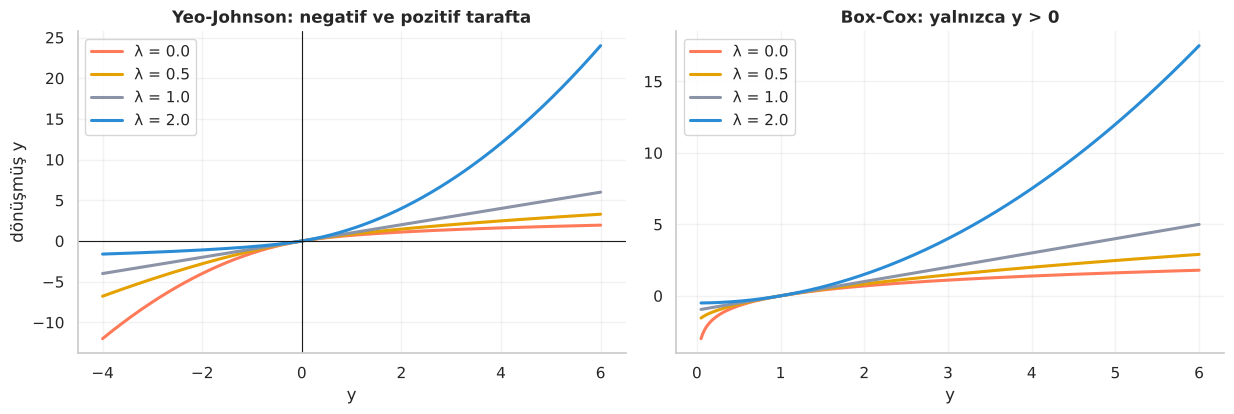

In [10]:
# ── Negatifli küçük liste: Box-Cox ✖, Yeo-Johnson ✔ ──────────
bakiye = np.array([-3.0, -1.0, 0.0, 1.0, 3.0])
try:
    stats.boxcox(bakiye)
except ValueError as hata:
    print("❌ Box-Cox:", hata)
yj0 = stats.yeojohnson(bakiye, lmbda=0.0)         # λ = 0 için Yeo-Johnson
print("✅ Yeo-Johnson (λ=0):", np.round(yj0, 3))
print("   Aynalı davranış: -1 ile +1 birbirinin simetriği ->", np.round(yj0[1], 3), "ve", np.round(yj0[3], 3))

# Eğri çizimi: farklı λ değerlerinde Yeo-Johnson, sayı doğrusunun tamamında
x = np.linspace(-4, 6, 300)
fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.3))
for lam, r in zip([0.0, 0.5, 1.0, 2.0], [RENK["mercan"], RENK["amber"], RENK["gri"], RENK["gok"]]):
    ax[0].plot(x, stats.yeojohnson(x, lmbda=lam), color=r, lw=2.2, label=f"λ = {lam}")
ax[0].axhline(0, color="k", lw=.8); ax[0].axvline(0, color="k", lw=.8)
ax[0].set_title("Yeo-Johnson: negatif ve pozitif tarafta"); ax[0].legend(); ax[0].set_xlabel("y"); ax[0].set_ylabel("dönüşmüş y")
xp = np.linspace(0.05, 6, 300)
for lam, r in zip([0.0, 0.5, 1.0, 2.0], [RENK["mercan"], RENK["amber"], RENK["gri"], RENK["gok"]]):
    ax[1].plot(xp, stats.boxcox(xp, lmbda=lam), color=r, lw=2.2, label=f"λ = {lam}")
ax[1].set_title("Box-Cox: yalnızca y > 0"); ax[1].legend(); ax[1].set_xlabel("y")
plt.tight_layout(); kaydet(fig, "kavram_05_yeo_johnson_egrileri"); plt.show()

<table><tr><td>

<img src="assets/etiket_ipucu.svg" height="34" alt="İpucu">

**Pratik kural:** Tüm değerler kesinlikle pozitifse **Box-Cox**; sıfır ya da negatif varsa **Yeo-Johnson**. Eskiden sıfırlı verilerde herkes «her değere 1 ekle, sonra Box-Cox» hilesini kullanırdı. Yeo-Johnson bu hileyi **resmî ve tutarlı** hâle getirir. scikit-learn'de ikisi de tek sınıftadır: `PowerTransformer(method="box-cox")` ve `PowerTransformer(method="yeo-johnson")`.

</td></tr></table>

<a id="k7"></a>

<p align="center">
  <img src="assets/kavram_07.svg" width="100%" alt="Durak 7 · Gidiş-dönüş">
</p>

### ↩️ 7.1 · Model Başka Dünyada Çalışır, Sonuç Dolara Döner

Dönüşüm bir **gidiş bileti**dir: model dönüşmüş dünyada öğrenir ve tahmin eder. Ama sigorta şirketine «3,7 birim» demek işe yaramaz; **dolar** istenir. Bu yüzden dönüşümün **ters yönü** de kullanılır.

<p align="center">
  <img src="assets/diyagram_geri_donus.svg" width="100%" alt="Gidiş-dönüş">
</p>

In [11]:
# ── Gidiş-dönüş testi ve "model tahmini" benzetmesi ──────────
pt = PowerTransformer(method="box-cox", standardize=True).fit(prim.reshape(-1, 1))
z = pt.transform(prim.reshape(-1, 1))
geri = pt.inverse_transform(z).ravel()
print(f"λ = {pt.lambdas_[0]:.3f} | gidiş-dönüş sonrası en büyük sapma: {np.abs(geri - prim).max():.2e} $ (yuvarlama hatası düzeyi)")

# Benzetme: bir model "dönüşmüş dünyada" 3 farklı kişi için şu sayıları tahmin etti
tahmin_z = np.array([[-1.2], [0.0], [2.1]])
print("Model (dönüşmüş dünya):", tahmin_z.ravel(), "→ dolara çevrilmiş:", pt.inverse_transform(tahmin_z).ravel().round(0))

λ = 0.044 | gidiş-dönüş sonrası en büyük sapma: 1.38e-10 $ (yuvarlama hatası düzeyi)
Model (dönüşmüş dünya): [-1.2  0.   2.1] → dolara çevrilmiş: [ 2954.  9120. 57938.]


### ⚖️ 7.2 · Küçük Ama Önemli Bir Uyarı: Ortalama mı, Ortanca mı?

Dönüşmüş dünyada **ortalamayı** alıp geri çevirirsek, dolar dünyasında **ortancaya yakın** bir sayı elde ederiz; ortalamayı değil. Çarpık veride ortanca, ortalamadan küçüktür. Bu yüzden ters dönüşümle elde edilen tahminler **hafif düşük kalabilir**.

<p align="center">
  <img src="assets/diyagram_ters_yanlilik.svg" width="100%" alt="Ters dönüşüm yanlılığı">
</p>

In [12]:
z_ort = z.mean()
geri_ort = pt.inverse_transform([[z_ort]])[0, 0]
print(f"Gerçek ortalama prim        : {prim.mean():>9,.0f} $")
print(f"Gerçek ortanca prim         : {np.median(prim):>9,.0f} $")
print(f"Dönüşmüş ortalamanın geri çevrilmişi: {geri_ort:>9,.0f} $   ← ortancaya yakın, ortalamadan düşük")

# "Smearing" düzeltmesi: dönüşmüş uzaydaki dağılımı da hesaba katıp ortalamaya yaklaşmak
smear = pt.inverse_transform(z_ort + (z - z_ort)).mean()
print(f"Dağılımı hesaba katan düzeltme       : {smear:>9,.0f} $   ← gerçek ortalamaya yakın")

Gerçek ortalama prim        :    13,279 $
Gerçek ortanca prim         :     9,386 $
Dönüşmüş ortalamanın geri çevrilmişi:     9,120 $   ← ortancaya yakın, ortalamadan düşük
Dağılımı hesaba katan düzeltme       :    13,279 $   ← gerçek ortalamaya yakın


<table><tr><td>

<img src="assets/etiket_ipucu.svg" height="34" alt="İpucu">

Tüm tahminleri değil, **tipik** (ortanca) davranışı anlamak istiyorsanız ters dönüşüm tam yerindedir. **Toplam maliyet** (ortalama) hesaplıyorsanız bu **hafif düşük kalma** etkisini bilmek ya da düzeltmek gerekir. Proje dersinde bunu gerçek modelde ölçeceğiz.

</td></tr></table>

<a id="k8"></a>

<p align="center">
  <img src="assets/kavram_08.svg" width="100%" alt="Durak 8 · Sızıntı tuzağı">
</p>

### 🛡️ 8.1 · λ da bir «öğrenilen şey»dir

λ verinin içinden **hesaplanır**; yani o da bir **öğrenmedir**. Eğer λ'yı **tüm veriden** (test kısmı dahil) hesaplarsak, test verisine **göz ucuyla bakmış** oluruz. Buna **veri sızıntısı** denir. Doğrusu: λ'yı **yalnızca eğitim kısmından** bulmak, test kısmına yalnızca **uygulamaktır**.

<p align="center">
  <img src="assets/diyagram_sizinti.svg" width="100%" alt="Sızıntı tuzağı">
</p>

Gerçek hayatta yeni gelen prim verisi **henüz yok**; λ'yı o veriden hesaplamak mümkün değildir. Doğrulama bu koşulu **taklit etmelidir**. Ayrıca küçük veride λ **kararsız** olabilir; bunu görelim:

💾 Kaydedildi → outputs/figures/kavram_06_lambda_kararliligi.png


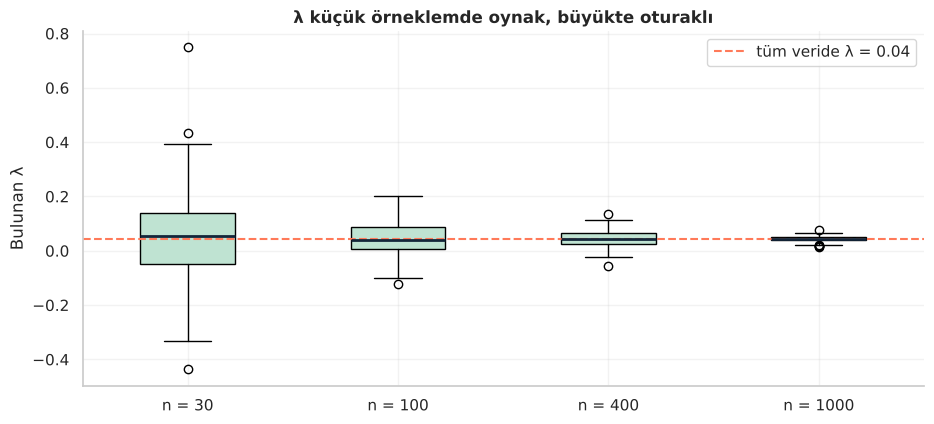

n =   30: λ ortancası +0.06 | %5–%95 aralığı -0.17 … +0.26
n =  100: λ ortancası +0.04 | %5–%95 aralığı -0.05 … +0.15
n =  400: λ ortancası +0.05 | %5–%95 aralığı +0.00 … +0.10
n = 1000: λ ortancası +0.04 | %5–%95 aralığı +0.03 … +0.06


In [13]:
# ── λ ne kadar kararlı? Farklı büyüklükte örneklerde 300'er kez bulalım ───
rng = np.random.RandomState(RANDOM_STATE)
boyutlar = [30, 100, 400, 1000]
sonuc = {n: [stats.boxcox_normmax(rng.choice(prim, n, replace=False), method="mle") for _ in range(300)] for n in boyutlar}

fig, ax = plt.subplots(figsize=(9.5, 4.4))
ax.boxplot([sonuc[n] for n in boyutlar], tick_labels=[f"n = {n}" for n in boyutlar], patch_artist=True,
           boxprops=dict(facecolor="#BFE3D2"), medianprops=dict(color=RENK["koyu"], lw=2))
ax.axhline(lam_en, color=RENK["mercan"], ls="--", label=f"tüm veride λ = {lam_en:.2f}"); ax.legend()
ax.set_title("λ küçük örneklemde oynak, büyükte oturaklı"); ax.set_ylabel("Bulunan λ")
plt.tight_layout(); kaydet(fig, "kavram_06_lambda_kararliligi"); plt.show()
for n in boyutlar:
    print(f"n = {n:>4}: λ ortancası {np.median(sonuc[n]):+.2f} | %5–%95 aralığı {np.percentile(sonuc[n], 5):+.2f} … {np.percentile(sonuc[n], 95):+.2f}")

<table><tr><td>

<img src="assets/etiket_dikkat.svg" height="34" alt="Dikkat">

Küçük örneklemde (n = 30) λ **geniş bir aralığa** savruluyor; yalnızca 30 kişiye bakıp «λ = 0,3» demek **şansa** bağlı. Bu yüzden: **(1)** λ'yı yalnızca eğitimden öğrenin, **(2)** küçük veride sonuca **temkinli** bakın, **(3)** λ'yı her doğrulama katında **yeniden** öğrenin (scikit-learn'in `TransformedTargetRegressor` sınıfı bunu otomatik yapar).

</td></tr></table>

<a id="k9"></a>

<p align="center">
  <img src="assets/kavram_09.svg" width="100%" alt="Durak 9 · Doğrusal mı, ağaç mı">
</p>

### 🌳 9.1 · Karar Ağacı Ölçeğe Bakmaz, Sıraya Bakar

Bir karar ağacı «BMI 30'dan büyük mü?» gibi sorular sorar. Bir sayıyı **sırasını bozmadan** dönüştürürsek (karekök, logaritma…), ağacın soruları **aynı kişileri** aynı gruplara ayırır. Yani **özellik dönüşümü ağaç için fark etmez**. Doğrusal modeller ise ölçeğe duyarlıdır.

<p align="center">
  <img src="assets/diyagram_agac_dogrusal.svg" width="100%" alt="Doğrusal ve ağaç">
</p>

In [14]:
# ── Deney 1: Özelliği dönüştürmek ağacı değiştirir mi? ───────
egitim, test = train_test_split(ham, test_size=0.2, random_state=RANDOM_STATE)
oz_ham = ["age", "bmi"]
A = egitim[oz_ham].to_numpy(); B = np.column_stack([np.log(egitim["age"]), np.sqrt(egitim["bmi"])])   # sırayı bozmayan dönüşümler
ağ_a = DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE).fit(A, egitim["charges"])
ağ_b = DecisionTreeRegressor(max_depth=5, random_state=RANDOM_STATE).fit(B, egitim["charges"])
fark_egitim = np.abs(ağ_a.predict(A) - ağ_b.predict(B)).max()
At = test[oz_ham].to_numpy(); Bt = np.column_stack([np.log(test["age"]), np.sqrt(test["bmi"])])
fark_test = np.abs(ağ_a.predict(At) - ağ_b.predict(Bt))
print(f"Eğitim satırlarında tahmin farkı (en büyük): {fark_egitim:.6f} $  → ağaç ölçek değişimini 'görmedi'")
print(f"Yeni satırlarda: {(fark_test > 0).sum()} / {len(test)} kişide küçük fark var (eşikler ara noktaya konur); ort. fark {fark_test.mean():.1f} $")

Eğitim satırlarında tahmin farkı (en büyük): 0.000000 $  → ağaç ölçek değişimini 'görmedi'
Yeni satırlarda: 1 / 268 kişide küçük fark var (eşikler ara noktaya konur); ort. fark 20.6 $


Şimdi **hedefi** (primin kendisini) dönüştürmenin **doğrusal modele** etkisine bakalım. Aynı veri, aynı model, tek fark: model dolar mı öğreniyor, yoksa Box-Cox'lu primi mi?

In [15]:
# ── Deney 2: Doğrusal modelde hedefi dönüştürmek ─────────────
from sklearn.compose import TransformedTargetRegressor

def oz(d):  # sade özellikler: yaş, BMI, çocuk, sigara
    return np.column_stack([d["age"], d["bmi"], d["children"], (d["smoker"] == "yes").astype(float)])

Xe, Xt = oz(egitim), oz(test); ye, yt = egitim["charges"].to_numpy(), test["charges"].to_numpy()
m_ham = LinearRegression().fit(Xe, ye)
m_bc = TransformedTargetRegressor(LinearRegression(), transformer=PowerTransformer("box-cox", standardize=True)).fit(Xe, ye)

def olc(yg, tah):
    rmsle = np.sqrt(np.mean((np.log1p(np.clip(tah, 0, None)) - np.log1p(yg)) ** 2))
    return {"RMSE ($)": mean_squared_error(yg, tah) ** .5, "MAE ($)": mean_absolute_error(yg, tah), "Göreli hata (RMSLE)": rmsle,
            "Negatif tahmin sayısı": int((tah < 0).sum())}

sonuc = pd.DataFrame({"Ham hedef": olc(yt, m_ham.predict(Xt)), "Box-Cox hedef": olc(yt, m_bc.predict(Xt))}).T
display(sonuc.round(3)); rapor_kaydet(sonuc, "kavram_01_dogrusal_hedef")

,RMSE ($),MAE ($),Göreli hata (RMSLE),Negatif tahmin sayısı
Ham hedef,5992.875,4198.593,0.833,2.0
Box-Cox hedef,6810.995,3727.777,0.404,0.0


📄 Rapor → outputs/reports/kavram_01_dogrusal_hedef.csv


💾 Kaydedildi → outputs/figures/kavram_07_artik_huni.png


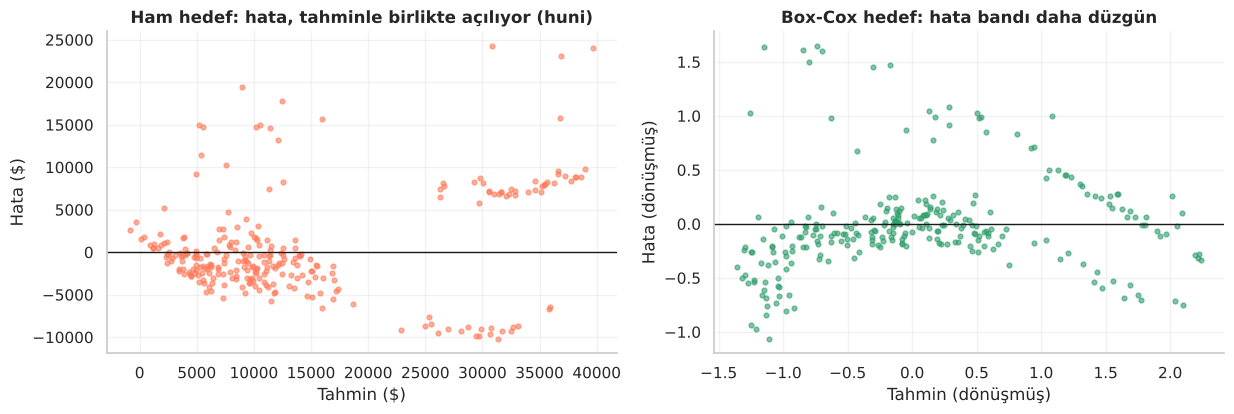

|hata| ile tahmin arasındaki ilişki (Spearman): ham +0.59 → Box-Cox -0.08   (0'a yakın = varyans sabit)


In [16]:
# ── Artıklar: "huni" gerçekten düzeliyor mu? ─────────────────
tah_ham = m_ham.predict(Xt)
zt = m_bc.transformer_.transform(yt.reshape(-1, 1)).ravel()
tah_z = m_bc.regressor_.predict(Xt)

fig, ax = plt.subplots(1, 2, figsize=(12.5, 4.3))
ax[0].scatter(tah_ham, yt - tah_ham, s=12, alpha=.6, color=RENK["mercan"]); ax[0].axhline(0, color="k", lw=1)
ax[0].set_title("Ham hedef: hata, tahminle birlikte açılıyor (huni)"); ax[0].set_xlabel("Tahmin ($)"); ax[0].set_ylabel("Hata ($)")
ax[1].scatter(tah_z, zt - tah_z, s=12, alpha=.6, color=RENK["nane"]); ax[1].axhline(0, color="k", lw=1)
ax[1].set_title("Box-Cox hedef: hata bandı daha düzgün"); ax[1].set_xlabel("Tahmin (dönüşmüş)"); ax[1].set_ylabel("Hata (dönüşmüş)")
plt.tight_layout(); kaydet(fig, "kavram_07_artik_huni"); plt.show()
r1 = stats.spearmanr(tah_ham, np.abs(yt - tah_ham))[0]; r2 = stats.spearmanr(tah_z, np.abs(zt - tah_z))[0]
print(f"|hata| ile tahmin arasındaki ilişki (Spearman): ham {r1:+.2f} → Box-Cox {r2:+.2f}   (0'a yakın = varyans sabit)")

<table><tr><td>

<img src="assets/etiket_icgoru.svg" height="34" alt="İçgörü">

**İki yüzlü sonuç:** Hedefi dönüştürmek **göreli hatayı** (RMSLE) ve **negatif tahminleri** düzeltir; hatanın tahminle birlikte açılan **huni** biçimini de azaltır. Ama **dolar cinsinden hatada** (RMSE, MAE) her zaman kazandırmaz: dönüşmüş dünyada küçük bir sapma, geri çevrilince **büyük primlerde büyük dolar hatası**na dönüşebilir. Hangi ölçüte göre kazandığınızı **baştan** belirlemek bu yüzden şarttır. Proje dersinde 27 algoritmada ölçeceğiz.

</td></tr></table>

<a id="k10"></a>

<p align="center">
  <img src="assets/kavram_10.svg" width="100%" alt="Durak 10 · Özet">
</p>

### 🧠 Akılda Kalacaklar

<table>
<tr><td width="33%" valign="top" align="center"><h3>📐</h3><b>Lastik cetvel</b><br><sub><i>büyükleri sıkıştır, küçükleri aç</i></sub><br><br>Çarpık veride birkaç dev değer ortalamayı çeker; dönüşüm kuyruğu içeri alır<br><br></td><td width="33%" valign="top" align="center"><h3>🎛️</h3><b>Tek düğme λ</b><br><sub><i>1: dokunma · 0,5: karekök · 0: log</i></sub><br><br>λ, verinin <b>çana en çok benzediği</b> noktaya göre bulunur<br><br></td><td width="33%" valign="top" align="center"><h3>➖</h3><b>Pozitif mi, değil mi?</b><br><sub><i>Box-Cox ya da Yeo-Johnson</i></sub><br><br>Sıfır ve negatif varsa <b>Yeo-Johnson</b><br><br></td></tr>
<tr><td width="33%" valign="top" align="center"><h3>↩️</h3><b>Gidiş-dönüş</b><br><sub><i>ters dönüşüm</i></sub><br><br>Tahmin dolara çevrilir; ortalama yerine <b>ortancaya yakın</b> çıkar<br><br></td><td width="33%" valign="top" align="center"><h3>🛡️</h3><b>λ öğrenilen bir şeydir</b><br><sub><i>yalnızca eğitimden</i></sub><br><br>Test verisinden λ bulmak sızıntıdır; küçük veride λ oynaktır<br><br></td><td width="33%" valign="top" align="center"><h3>🌳</h3><b>Herkes yararlanmaz</b><br><sub><i>ağaç sıraya bakar</i></sub><br><br>Özellik dönüşümü ağaçta fark etmez; hedef dönüşümü <b>ölçüte</b> göre değerlendirilir<br><br></td></tr>
</table>

### ❓ Quiz (cevaplar açılır kutularda)

<details><summary><b>1.</b> Ortalama neden çarpık veride «tipik» değeri temsil etmeyebilir?</summary>

Birkaç çok büyük değer ortalamayı yukarı çeker. Kafe örneğinde dokuz kişi 10 $, bir kişi 1.000 $ harcadığında ortalama 109 $ olur; masada kimse o kadar harcamamıştır. Ortanca bu durumda daha dayanıklı bir özettir.
</details>

<details><summary><b>2.</b> Box-Cox'ta λ = 0 hangi dönüşüme karşılık gelir? λ = 1 ne yapar?</summary>

λ = 0 doğal logaritmadır. λ = 1 veriyi pratikte değiştirmez (yalnızca 1 çıkarır, yani kaydırır).
</details>

<details><summary><b>3.</b> Verimizde sıfırlar varsa neden Box-Cox yerine Yeo-Johnson seçeriz?</summary>

Box-Cox yalnızca kesinlikle pozitif değerlerle çalışır; sıfır ya da negatifte hata verir. Yeo-Johnson tüm gerçek sayılarda çalışacak şekilde genişletilmiştir.
</details>

<details><summary><b>4.</b> λ'yı tüm veriden hesaplayıp sonra bölmek neden yanlıştır?</summary>

λ verinin içinden öğrenilen bir değerdir. Test kısmı da hesaba katılırsa test verisinin bilgisi eğitime sızar ve skor iyimser çıkar. Doğrusu λ'yı eğitim kısmında bulup teste yalnızca uygulamaktır.
</details>

<details><summary><b>5.</b> Karar ağacı için bir özelliği logaritmaya çevirmek neden fark etmez?</summary>

Ağaç yalnızca değerlerin sırasına göre bölme yapar; sırayı bozmayan bir dönüşüm aynı kişileri aynı gruplara ayırır.
</details>

<details><summary><b>6.</b> Hedefi Box-Cox'la dönüştürüp tahmini geri çevirince neden dolar hatası artabilir?</summary>

Dönüşmüş dünyadaki küçük sapma, ters dönüşümde büyük değerlerde güçlenir (üssel gibi davranır). Dolar hatası da zaten büyük primlerden etkilenir; bu yüzden göreli hata iyileşirken dolar hatası kötüleşebilir.
</details>

### 🏠 Ödevler

1. **λ avı:** `children` dışındaki sütunlardan birini (örneğin `bmi`) seçin; `boxcox_normmax` ile λ'sını bulun, öncesi-sonrası çarpıklığını karşılaştırın. λ'nın güven aralığı 1'i içeriyorsa dönüşüm gerekli mi?
2. **Lastiği kendiniz gerin:** 3. durağın animasyonunu λ = 1 → 2 aralığı için yeniden çizin. Büyük λ'lar çarpıklığa ne yapıyor?
3. **Küçük örneklem:** 8. durağın deneyini `bmi` sütunuyla tekrarlayın. λ hangi örneklem büyüklüğünde oturaklı hâle geliyor?
4. **Negatif dünya:** Kendi uydurduğunuz, negatif değerler içeren çarpık bir liste üretin (örneğin `np.random.default_rng(0).standard_exponential(500) * 4 - 2`); Yeo-Johnson uygulayıp Q-Q çizin.
5. **Ortanca-ortalama:** 7. durağın smearing hesabını `prim` yerine `bmi` ile yapın. Fark ne kadar küçülüyor? Neden?

### 📚 Kaynakça

Bu ders notundaki fikirler aşağıdaki kaynaklara dayanır. Dolaylı (ikincil) aktarımlar metinde «…'den aktarma» ile belirtilmiştir.

- Atkinson, A. C., Riani, M., & Corbellini, A. (2021). The Box–Cox transformation: Review and extensions. *Statistical Science, 36*(2), 239–255. https://doi.org/10.1214/20-STS778
- Box, G. E. P., & Cox, D. R. (1964). An analysis of transformations. *Journal of the Royal Statistical Society: Series B (Methodological), 26*(2), 211–252. https://doi.org/10.1111/j.2517-6161.1964.tb00553.x
- Lantz, B. (2013). *Machine learning with R*. Packt Publishing. (Sigorta veri setinin özgün kaynağı)
- Pedregosa, F., Varoquaux, G., Gramfort, A., Michel, V., Thirion, B., Grisel, O., … Duchesnay, É. (2011). Scikit-learn: Machine learning in Python. *Journal of Machine Learning Research, 12*, 2825–2830.
- Raymaekers, J., & Rousseeuw, P. J. (2024). Transforming variables to central normality. *Machine Learning, 113*(8), 4953–4975. https://doi.org/10.1007/s10994-021-05960-5
- Virtanen, P., Gommers, R., Oliphant, T. E., Haberland, M., Reddy, T., Cournapeau, D., … SciPy 1.0 Contributors. (2020). SciPy 1.0: Fundamental algorithms for scientific computing in Python. *Nature Methods, 17*, 261–272. https://doi.org/10.1038/s41592-019-0686-2
- Yeo, I.-K., & Johnson, R. A. (2000). A new family of power transformations to improve normality or symmetry. *Biometrika, 87*(4), 954–959. https://doi.org/10.1093/biomet/87.4.954

<p align="center">
  <img src="assets/kapanis_kavram.svg" width="100%" alt="Kapanış">
</p>